# SSNE | Lab 4 | Regularyzacje / przeuczenie / tips & tricks

## Prerequisites

In [1]:
!pip install torchvision seaborn tqdm

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 4.9 MB/s eta 0:00:005.2 MB/s eta 0:00:01
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.1/8.1 MB 10.5 MB/s eta 0:00:00m eta 0:00:010:0101


In [2]:
import torch, torchvision
from torchvision import transforms
import torch.nn as nn
import torch.optim as optim
import torch.functional as F
import numpy as np
import pandas as pd
import torch.utils.data as data
import seaborn as sns
import matplotlib.pyplot as plt
import os
import random
from tqdm import tqdm

In [3]:
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)
    torch.cuda.manual_seed_all(42)  # multi-GPU
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True)

# os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # wymagane przez niektóre operacje CUDA

## Trick #1 - Batch Normalization // BatchNorm
Batch-Normalization is an algorithmic method which makes the training of Deep Neural Networks (DNN) faster and more stable. 

In [4]:
# data.csv from Mini-Projekt 1

train_data = pd.read_csv("https://drive.google.com/uc?export=download&id=19lok0wZOqUThdF8wv_hnVIaIQ-VRD0RV",index_col=0)
train = train_data.drop(columns=["casual","registered","cnt","dteday","season","yr","mnth"])
print(train_data.shape)
print(train_data.values[:,-1].shape)
train_dataset = data.TensorDataset(torch.from_numpy(train.values).float(),torch.from_numpy(train_data.values[:,-1].astype(float)).float())
data_loader  = data.DataLoader(train_dataset, batch_size=256, shuffle=True)

(10886, 16)
(10886,)


In [5]:
class MyNet(nn.Module):
    def __init__(self):
        super(MyNet, self).__init__()
        self.lin1 =nn.Linear(9, 48)
        self.act1 =nn.ReLU()
        self.lin2 =nn.Linear(48, 24)
        self.act2 =nn.ReLU()
        self.lin3 =nn.Linear(24, 1)


    def forward(self, x):
        x = self.lin1(x)
        x = self.act1(x)
        x = self.lin2(x)
        x = self.act2(x)
        x = self.lin3(x)
        return x

In [6]:
class MyNetBN(nn.Module):
    def __init__(self):
        super(MyNetBN, self).__init__()
        self.lin1 =nn.Linear(9, 48)  # 28 x 28 = 784
        self.bn1 = nn.BatchNorm1d(48)
        self.act1 =nn.ReLU()
        self.lin2 =nn.Linear(48, 24)
        self.bn2 = nn.BatchNorm1d(24)
        self.act2 =nn.ReLU()
        self.lin3 =nn.Linear(24, 1)


    def forward(self, x):
        x = self.lin1(x)
        x = self.bn1(x)
        x = self.act1(x)
        x = self.lin2(x)
        x = self.bn2(x)
        x = self.act2(x)
        x = self.lin3(x)
        return x

In [7]:
model = MyNet()
print(model)
model_bn = MyNetBN()
print(model_bn)

MyNet(
  (lin1): Linear(in_features=9, out_features=48, bias=True)
  (act1): ReLU()
  (lin2): Linear(in_features=48, out_features=24, bias=True)
  (act2): ReLU()
  (lin3): Linear(in_features=24, out_features=1, bias=True)
)
MyNetBN(
  (lin1): Linear(in_features=9, out_features=48, bias=True)
  (bn1): BatchNorm1d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (act1): ReLU()
  (lin2): Linear(in_features=48, out_features=24, bias=True)
  (bn2): BatchNorm1d(24, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (act2): ReLU()
  (lin3): Linear(in_features=24, out_features=1, bias=True)
)


In [8]:
loss_fn = nn.MSELoss()
opt = optim.SGD(model.parameters(), lr=0.0001, momentum=0.5)
opt_bn = optim.SGD(model_bn.parameters(), lr=0.0001, momentum=0.5)

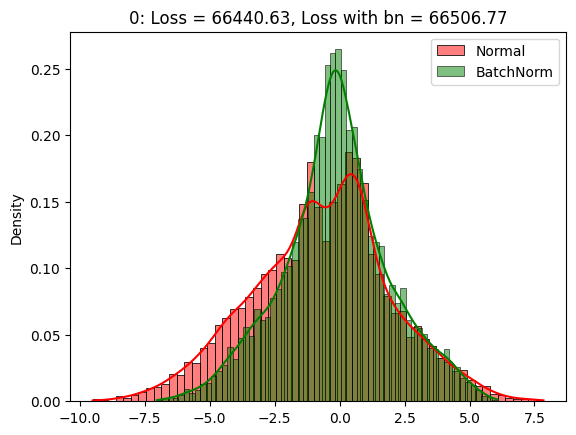

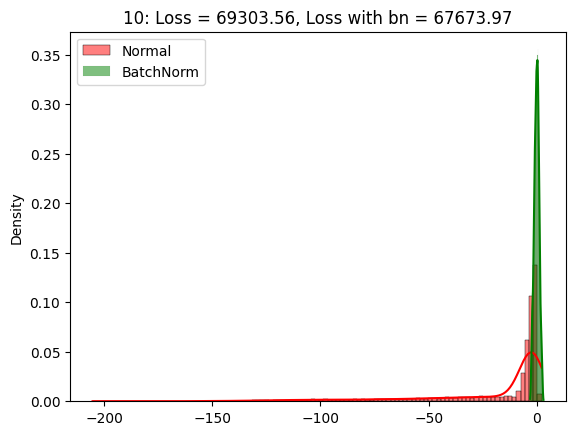

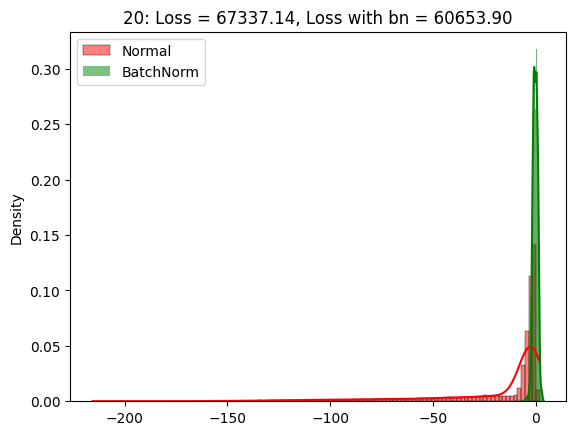

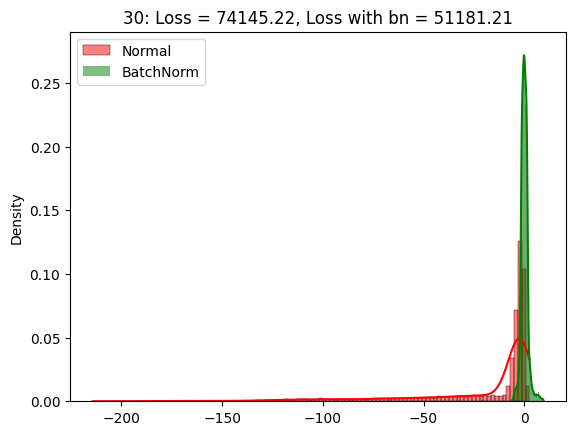

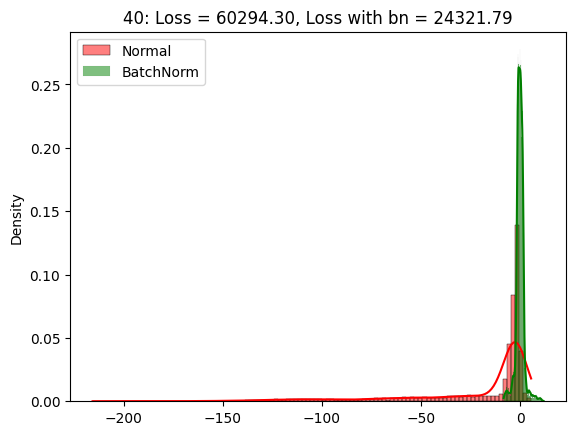

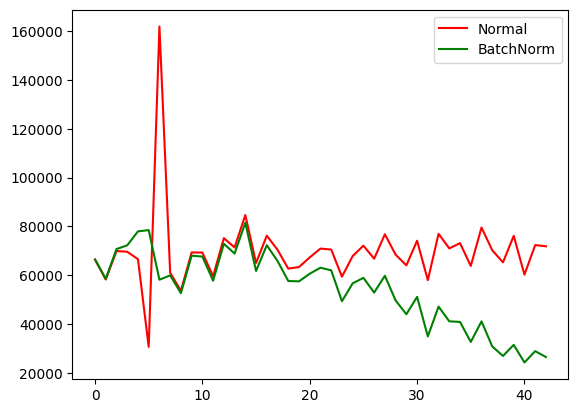

----------------------


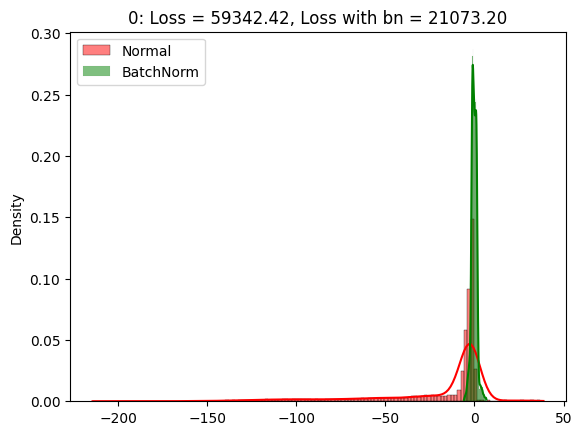

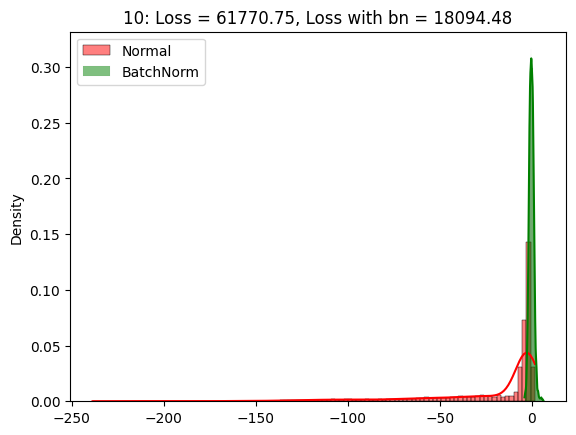

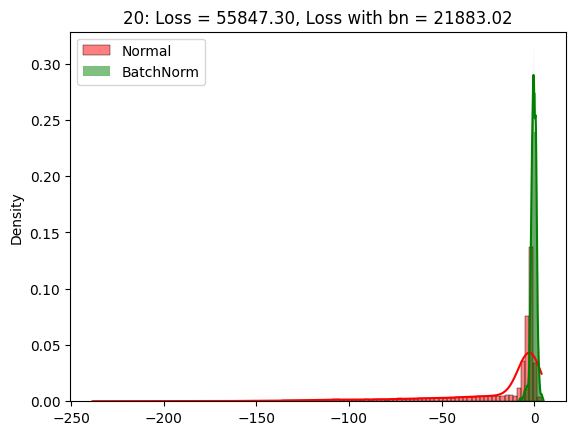

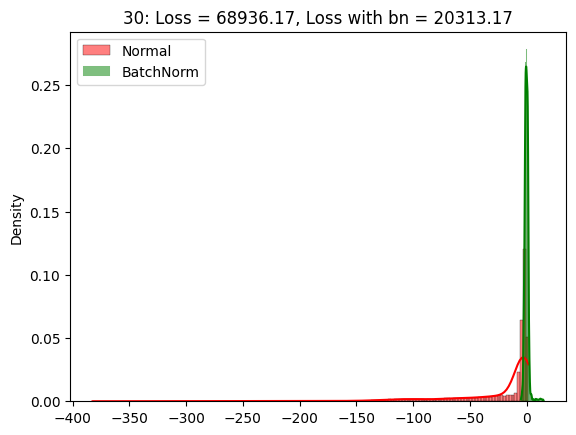

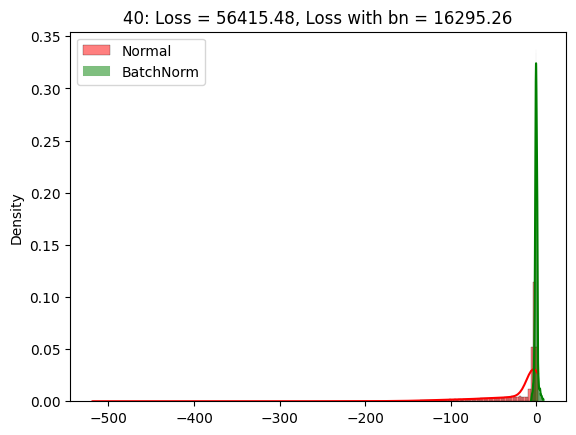

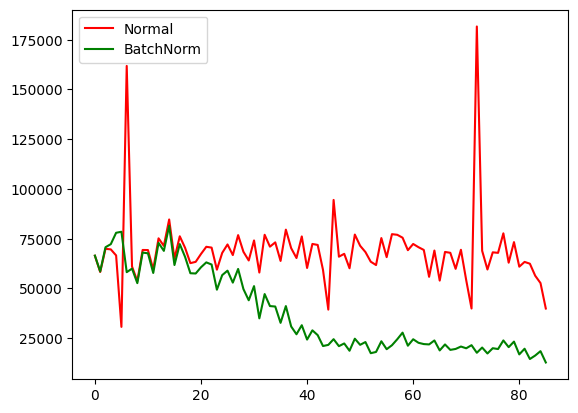

----------------------


In [9]:
loss_arr = []
loss_bn_arr = []
max_epochs = 2

for epoch in range(max_epochs):
    for i, batch in enumerate(data_loader, 0):

        inputs, labels = batch

        # training steps for normal model
        opt.zero_grad()
        outputs = model(inputs).squeeze()
        loss = loss_fn(outputs, labels)
        loss.backward()
        opt.step()

        # training steps for bn model
        opt_bn.zero_grad()
        outputs_bn = model_bn(inputs).squeeze()
        loss_bn = loss_fn(outputs_bn, labels)
        loss_bn.backward()
        opt_bn.step()

        loss_arr.append(loss.item())
        loss_bn_arr.append(loss_bn.item())

        if i % 10 == 0:

            inputs = inputs.view(inputs.size(0), -1)

            model.eval()
            model_bn.eval()

            a = model.lin1(inputs)
            a = a.detach().numpy().ravel()
            sns.histplot(a, kde=True, color='r', label='Normal', stat="density")

            b = model_bn.lin1(inputs)
            b = model_bn.bn1(b)
            b = b.detach().numpy().ravel()

            sns.histplot(b, kde=True, color='g', label='BatchNorm', stat="density")
            plt.title('%d: Loss = %0.2f, Loss with bn = %0.2f' % (i, loss.item(), loss_bn.item()))
            plt.legend()
            plt.show()
            plt.pause(0.5)

            model.train()
            model_bn.train()



    plt.plot(loss_arr, 'r', label='Normal')
    plt.plot(loss_bn_arr, 'g', label='BatchNorm')
    plt.legend()
    plt.show()
    print('----------------------')

Visualisation from AI by Hand [here](https://www.byhand.ai/p/batch-normalization-by-hand).

In [10]:
print(f"{model_bn.lin1=}")
print(f"{model_bn.bn1=}")
print(f"-----------------")
print(f"Running mean: {model_bn.bn1.running_mean.data}")
print(f"Running std: {model_bn.bn1.running_var.data}")
print(f"-----------------")
print(f"Scale: {model_bn.bn1.weight.data}")
print(f"Shift: {model_bn.bn1.bias.data}")


model_bn.lin1=Linear(in_features=9, out_features=48, bias=True)
model_bn.bn1=BatchNorm1d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
-----------------
Running mean: tensor([-22.6743,   6.9670,  -2.7774,  -0.8633,  19.8771, -13.5351,  -9.8361,
         -2.0873,  -1.8205,  -5.1050, -18.9004,   2.1180,  -7.5844,   7.5545,
         -0.6122,  -3.7076,  -3.0329,  -9.4377,  -1.9402,  -8.5717,   2.9132,
         -1.8443,  -3.1745,  -3.3723,  -4.2505,  -3.9706,   8.8887,  -7.0628,
         -2.2266,  28.4924,  14.7615,  29.0868,  -3.4719,   1.8210,  -2.0231,
         -3.5321,  15.7713,   2.8487,   6.6491,  -3.1512,  -4.1808,   0.1865,
         -3.5691,  18.2848,  13.0798, -16.2413, -38.1305,  -3.2868])
Running std: tensor([190.8251,  73.9101,   4.3688,   1.1601, 139.7537,  74.6262,  41.7292,
          4.0457,   2.1786,  11.0968, 131.7863,   2.6583,  22.1307,  18.9534,
          1.8029,   4.5181,   3.2522,  37.9736,   1.9790,  24.8233,   7.4138,
          2.0776,   3.9598,

1. During training:
- Inputs?
- Running mean and std?
- Scale and shift?

2. During evaluation:
- Inputs?
- Running mean and std?
- Scale and shift?


![](https://forums.fast.ai/uploads/default/original/2X/9/998a1be6463260f731481106756034c42040e256.jpg)

- BatchNorm and Dropout are not updated during model.eval() stage, statistics learned during model.train() stage are used during model.eval() operations

## Przeuczanie sieci

In [11]:
mnist_data = torchvision.datasets.MNIST('data', train=True, download=True, transform=transforms.ToTensor())
mnist_data = list(mnist_data)
mnist_train = mnist_data[:20]
mnist_val   = mnist_data[20:1000]

100%|██████████| 9.91M/9.91M [00:01<00:00, 7.35MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 178kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 1.85MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.84MB/s]


In [12]:
mnist_train[0]

(tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 

In [19]:
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)
    torch.cuda.manual_seed_all(42)

torch.backends.cudnn.determinstic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.mps.is_available() else "cpu")
device

device(type='mps')

In [14]:
class MNISTClassifier(nn.Module):
    def __init__(self):
        super(MNISTClassifier, self).__init__()
        self.layer1 = nn.Linear(28 * 28, 800)
        self.act_1 =  nn.Tanh()
        self.layer2 = nn.Linear(800, 800)
        self.act_2 = nn.Tanh()
        self.layer3 = nn.Linear(800, 10)
    def forward(self, img):
        flattened = img.view(-1, 28 * 28)
        activation1 = self.act_1(self.layer1(flattened))
        activation2 = self.act_2(self.layer2(activation1))
        output = self.layer3(activation2)
        return output

In [15]:
def train(model, train, valid, batch_size=10, num_epochs=1, learn_rate=0.001, weight_decay=0, with_plot=False):
    train_loader = torch.utils.data.DataLoader(train,
                                               batch_size=batch_size,
                                               shuffle=True) # shuffle after every epoch
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=learn_rate,momentum=0.9, weight_decay=weight_decay)

    iters, losses, train_acc, val_acc = [], [], [], []

    # training
#     n = 0 # the number of iterations
    idx = 0
    for n in range(num_epochs):
        for imgs, labels in iter(train_loader):
            imgs, labels = imgs.to(device), labels.to(device)
            model.train()
            out = model(imgs)             # forward pass
            loss = criterion(out, labels) # compute the total loss
            loss.backward()               # backward pass (compute parameter updates)
            optimizer.step()              # make the updates for each parameter
            optimizer.zero_grad()

            # save the current training information
            if idx % 10 == 9:
                iters.append(idx)
                losses.append(float(loss)/batch_size)        # compute *average* loss
                train_acc.append(get_accuracy(model, train)) # compute training accuracy
                val_acc.append(get_accuracy(model, valid))   # compute validation accuracy
            idx+=1
        if n%100==0:
            print(f"Epoch {n}, loss: {loss.item()}")


    if with_plot:
        # plotting
        plt.figure(figsize=(10,4))
        plt.subplot(1,2,1)
        plt.title("Training Curve")
        plt.plot(iters, losses, label="Train")
        plt.xlabel("Iterations")
        plt.ylabel("Loss")

        plt.subplot(1,2,2)
        plt.title("Training Curve")
        plt.plot(iters, train_acc, label="Train")
        plt.plot(iters, val_acc, label="Validation")
        plt.xlabel("Iterations")
        plt.ylabel("Training Accuracy")
        plt.legend(loc='best')
        plt.show()


    print("Final Training Accuracy: {}".format(train_acc[-1]))
    print("Final Validation Accuracy: {}".format(val_acc[-1]))


train_acc_loader = torch.utils.data.DataLoader(mnist_train, batch_size=100)
val_acc_loader = torch.utils.data.DataLoader(mnist_val, batch_size=1000)

def get_accuracy(model, data):
    correct = 0
    total = 0
    model.eval() #*********#
    for imgs, labels in torch.utils.data.DataLoader(data, batch_size=64):
        imgs, labels = imgs.to(device), labels.to(device)
        output = model(imgs)
        pred = output.max(1, keepdim=True)[1] # get the index of the max logit
        correct += pred.eq(labels.view_as(pred)).sum().item()
        total += imgs.shape[0]
    return correct / total

Epoch 0, loss: 2.2941436767578125
Epoch 100, loss: 0.5520028471946716
Epoch 200, loss: 0.10244065523147583
Epoch 300, loss: 0.05089162662625313
Epoch 400, loss: 0.026985179632902145
Epoch 500, loss: 0.02074718102812767
Epoch 600, loss: 0.013810336589813232
Epoch 700, loss: 0.014680477790534496
Epoch 800, loss: 0.010369231924414635
Epoch 900, loss: 0.006675117649137974


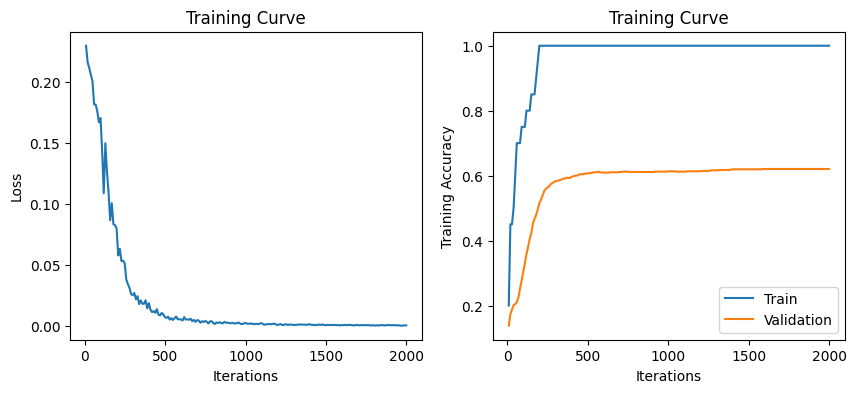

Final Training Accuracy: 1.0
Final Validation Accuracy: 0.6204081632653061


In [21]:
model = MNISTClassifier().to(device)
train(model, mnist_train, mnist_val, num_epochs=1000, with_plot=True)

## Trick #2 - Dropout
Maskowanie losowych neuronów w sieci.
Dropout inaczej się w train() i eval().

+ Dropout oryginalnie: [Dropout: A Simple Way to Prevent Neural Networks from Overfitting](https://jmlr.org/papers/v15/srivastava14a.html)

![obrazek](https://miro.medium.com/1*o9j9haCPmXfTBK-qrUJbsQ.png)

+ Dropout w [PyTorchu](https://docs.pytorch.org/docs/stable/generated/torch.nn.Dropout.html)

In [22]:
m = nn.Dropout(p=0.5)
x = torch.randn((1, 6))

m.train()
print(f"x:     {x}")
print(f"train: {m(x)}")         # 1 / (1 - 0.5) = 2

m.eval()
print(f"eval:  {m(x)}")

x:     tensor([[-0.1006,  0.0824, -1.7545, -0.8445, -0.6222, -1.4087]])
train: tensor([[-0.0000,  0.0000, -3.5090, -0.0000, -0.0000, -2.8174]])
eval:  tensor([[-0.1006,  0.0824, -1.7545, -0.8445, -0.6222, -1.4087]])


In [24]:
class MNISTClassifier_Dropout(nn.Module):
    def __init__(self):
        super(MNISTClassifier_Dropout, self).__init__()
        self.layer1 = nn.Linear(28 * 28, 800)
        self.act_1 =  nn.Tanh()
        self.d1 = nn.Dropout(0.8)

        self.layer2 = nn.Linear(800, 800)
        self.act_2 = nn.Tanh()
        self.d2 = nn.Dropout(0.8)

        self.layer3 = nn.Linear(800, 10)
    
    def forward(self, img):
        flattened = img.view(-1, 28 * 28)
        activation1 = self.act_1(self.layer1(flattened))
        x = self.d1(activation1)
        activation2 = self.act_2(self.layer2(x))
        x = self.d2(activation2)
        output = self.layer3(x)
        return output

Epoch 0, loss: 2.2039599418640137
Epoch 100, loss: 1.0177936553955078
Epoch 200, loss: 0.2526274621486664
Epoch 300, loss: 0.10915891081094742
Epoch 400, loss: 0.033295728266239166
Epoch 500, loss: 0.020477021113038063
Epoch 600, loss: 0.028986018151044846
Epoch 700, loss: 0.013713458552956581
Epoch 800, loss: 0.0054732756689190865
Epoch 900, loss: 0.011388364247977734


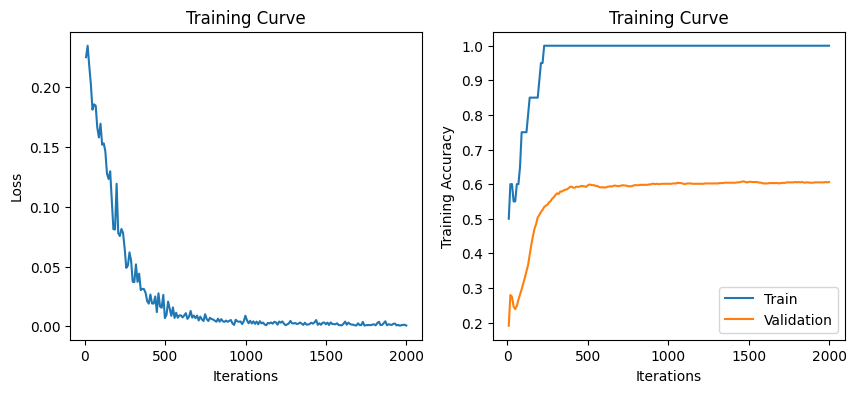

Final Training Accuracy: 1.0
Final Validation Accuracy: 0.6061224489795919


In [25]:
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)
    torch.cuda.manual_seed_all(42)

model = MNISTClassifier_Dropout().to(device)
train(model, mnist_train, mnist_val, num_epochs=1000, with_plot=True)

## Trick #3 - regularyzacja wag

### L1 vs L2 Regularization

![](https://miro.medium.com/v2/resize:fit:1400/format:webp/1*Tyu8vrwWsm0qJ4BhrSdAFA.png)



W torch: domyślnie L2 jako `weight_decay`

Epoch 0, loss: 2.2039616107940674
Epoch 100, loss: 1.058907151222229
Epoch 200, loss: 0.283914715051651
Epoch 300, loss: 0.13325515389442444
Epoch 400, loss: 0.046792007982730865
Epoch 500, loss: 0.03260369226336479
Epoch 600, loss: 0.04525057598948479
Epoch 700, loss: 0.024899186566472054
Epoch 800, loss: 0.013375518843531609
Epoch 900, loss: 0.027438919991254807


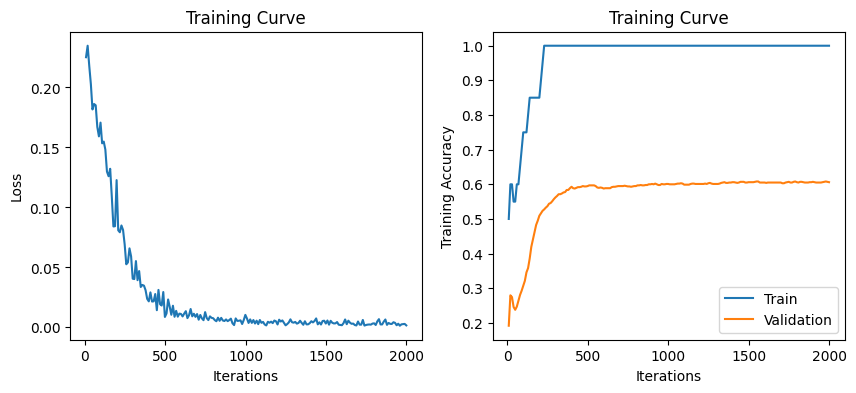

Final Training Accuracy: 1.0
Final Validation Accuracy: 0.6061224489795919


In [26]:
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)
    torch.cuda.manual_seed_all(42)

model = MNISTClassifier_Dropout().to(device)
train(model, mnist_train, mnist_val, num_epochs=1000, weight_decay=1e-2, with_plot=True)

### Zadanie - własna regularyzacja

In [39]:
class MNISTClassifier(nn.Module):
    def __init__(self):
        super(MNISTClassifier, self).__init__()
        self.layer1 = nn.Linear(28 * 28, 800)
        self.act_1 =  nn.Tanh()
        self.layer2 = nn.Linear(800, 800)
        self.act_2 = nn.Tanh()
        self.layer3 = nn.Linear(800, 10)
    def forward(self, img):
        flattened = img.view(-1, 28 * 28)
        activation1 = self.act_1(self.layer1(flattened))
        activation2 = self.act_2(self.layer2(activation1))
        output = self.layer3(activation2)
        return output

In [40]:
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)
    torch.cuda.manual_seed_all(42)

# model / optimizer
model = MNISTClassifier().to(device)

#### Without L1 Regularization

Epoch 0
Epoch 100
Epoch 200
Epoch 300
Epoch 400
Epoch 500
Epoch 600
Epoch 700
Epoch 800
Epoch 900


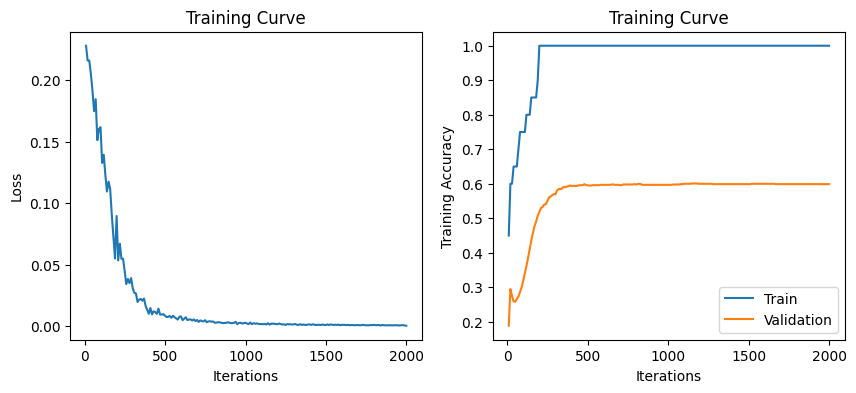

Final Training Accuracy: 1.0
Final Validation Accuracy: 0.5989795918367347


In [41]:

train_loader = torch.utils.data.DataLoader(mnist_train, batch_size=10, shuffle=True) # shuffle after every epoch
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

iters, losses, train_acc, val_acc = [], [], [], []

idx = 0
for n in range(1000):
    for imgs, labels in iter(train_loader):
        imgs, labels = imgs.to(device), labels.to(device)
        model.train()
        out = model(imgs)

        loss = criterion(out, labels)
        
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        if idx % 10 == 9:
            iters.append(idx)
            losses.append(float(loss)/10)        # compute *average* loss
            train_acc.append(get_accuracy(model, mnist_train)) # compute training accuracy
            val_acc.append(get_accuracy(model, mnist_val))   # compute validation accuracy
        idx+=1
    if n%100==0:
        print(f"Epoch {n}")

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.title("Training Curve")
plt.plot(iters, losses, label="Train")
plt.xlabel("Iterations")
plt.ylabel("Loss")

plt.subplot(1,2,2)
plt.title("Training Curve")
plt.plot(iters, train_acc, label="Train")
plt.plot(iters, val_acc, label="Validation")
plt.xlabel("Iterations")
plt.ylabel("Training Accuracy")
plt.legend(loc='best')
plt.show()


print("Final Training Accuracy: {}".format(train_acc[-1]))
print("Final Validation Accuracy: {}".format(val_acc[-1]))

#### With L1 Regularization

In [44]:
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)
    torch.cuda.manual_seed_all(42)

# model / optimizer
model = MNISTClassifier().to(device)

Epoch 0, CE: 2.2816, L1: 22658.0723
Epoch 100, CE: 0.9548, L1: 22527.2422
Epoch 200, CE: 0.1675, L1: 22405.2949
Epoch 300, CE: 0.0789, L1: 22216.4980
Epoch 400, CE: 0.0394, L1: 22003.0078
Epoch 500, CE: 0.0255, L1: 21779.8438
Epoch 600, CE: 0.0250, L1: 21552.3145
Epoch 700, CE: 0.0125, L1: 21322.7539
Epoch 800, CE: 0.0113, L1: 21092.3535
Epoch 900, CE: 0.0123, L1: 20861.8047


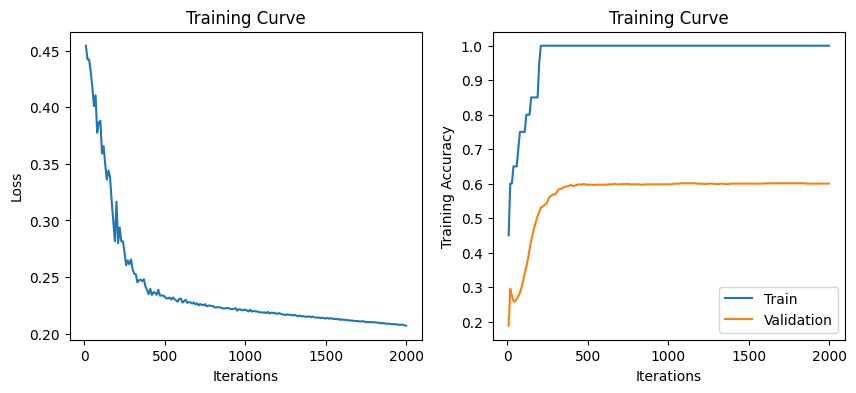

Final Training Accuracy: 1.0
Final Validation Accuracy: 0.6


In [45]:
train_loader = torch.utils.data.DataLoader(mnist_train, batch_size=10, shuffle=True) # shuffle after every epoch
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

iters, losses, train_acc, val_acc = [], [], [], []

REGULARIZATION_LAMBDA = 1e-4

idx = 0
for n in range(1000):
    for imgs, labels in iter(train_loader):
        imgs, labels = imgs.to(device), labels.to(device)
        model.train()
        out = model(imgs)

        l1_penalty = torch.tensor(0.0, device=device)
        for name, weights in model.named_parameters():
            if "weight" in name:
                l1_penalty += torch.sum(torch.abs(weights))

        data_loss = criterion(out, labels)
        loss = data_loss + REGULARIZATION_LAMBDA * l1_penalty

        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        if idx % 10 == 9:
            iters.append(idx)
            losses.append(float(loss / 10))
            train_acc.append(get_accuracy(model, mnist_train)) # compute training accuracy
            val_acc.append(get_accuracy(model, mnist_val))   # compute validation accuracy
        idx+=1
    if n%100==0:
        print(f"Epoch {n}, CE: {data_loss.item():.4f}, L1: {l1_penalty.item():.4f}")

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.title("Training Curve")
plt.plot(iters, losses, label="Train")
plt.xlabel("Iterations")
plt.ylabel("Loss")

plt.subplot(1,2,2)
plt.title("Training Curve")
plt.plot(iters, train_acc, label="Train")
plt.plot(iters, val_acc, label="Validation")
plt.xlabel("Iterations")
plt.ylabel("Training Accuracy")
plt.legend(loc='best')
plt.show()


print("Final Training Accuracy: {}".format(train_acc[-1]))
print("Final Validation Accuracy: {}".format(val_acc[-1]))

## Wielkość sieci a jej jakość

In [46]:
def set_seed(seed):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

In [47]:
class MNISTClassifier_parametrized(nn.Module):
    def __init__(self,size_1,size_2):
        super(MNISTClassifier_parametrized, self).__init__()
        self.layer1 = nn.Linear(28 * 28, size_1)
        self.act_1 =  nn.Tanh()
        self.layer2 = nn.Linear(size_1, size_2)
        self.act_2 = nn.Tanh()
        self.layer3 = nn.Linear(size_2, 10)
    def forward(self, img):
        flattened = img.view(-1, 28 * 28)
        activation1 = self.act_1(self.layer1(flattened))
        activation2 = self.act_2(self.layer2(activation1))
        output = self.layer3(activation2)
        return output

Epoch 0, loss: 2.32747220993042
Epoch 100, loss: 0.18253162503242493
Epoch 200, loss: 0.04377235099673271
Epoch 300, loss: 0.025961602106690407
Epoch 400, loss: 0.013391775079071522
Epoch 500, loss: 0.009858345612883568
Epoch 600, loss: 0.007617391645908356
Epoch 700, loss: 0.006659184582531452
Epoch 800, loss: 0.0070130228996276855
Epoch 900, loss: 0.006383529398590326


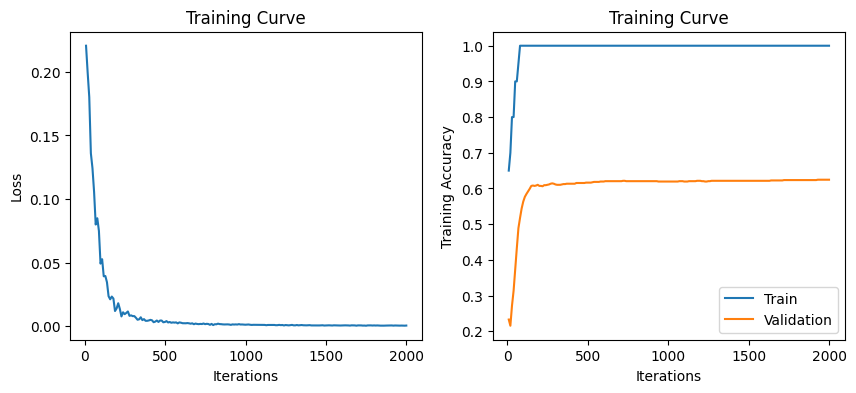

Final Training Accuracy: 1.0
Final Validation Accuracy: 0.6244897959183674


In [48]:
set_seed(42)
model = MNISTClassifier_parametrized(5000,3000).to(device)
train(model, mnist_train, mnist_val, num_epochs=1000, with_plot=True)

Epoch 0, loss: 2.301107883453369
Epoch 100, loss: 0.4210238456726074
Epoch 200, loss: 0.10196711122989655
Epoch 300, loss: 0.051473427563905716
Epoch 400, loss: 0.025365492329001427
Epoch 500, loss: 0.0181246567517519
Epoch 600, loss: 0.010204171761870384
Epoch 700, loss: 0.01143745519220829
Epoch 800, loss: 0.008460761979222298
Epoch 900, loss: 0.008747133426368237


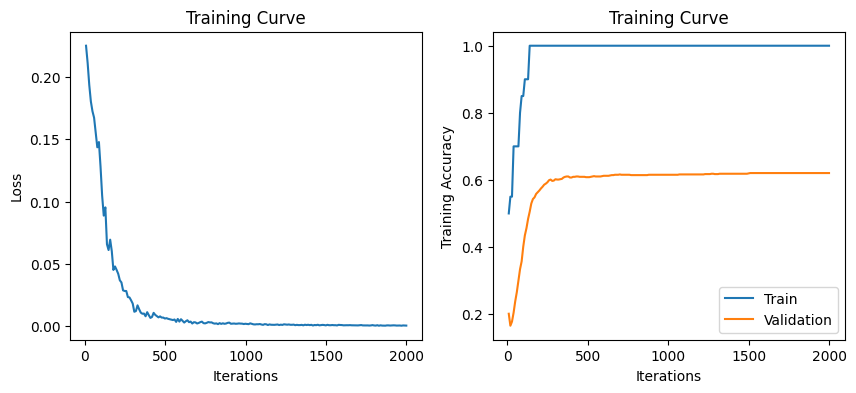

Final Training Accuracy: 1.0
Final Validation Accuracy: 0.6204081632653061


In [49]:
set_seed(42)
model = MNISTClassifier_parametrized(2000,1000).to(device)
train(model, mnist_train, mnist_val, num_epochs=1000, with_plot=True)

Epoch 0, loss: 2.2708826065063477
Epoch 100, loss: 0.9515225291252136
Epoch 200, loss: 0.25105154514312744
Epoch 300, loss: 0.07852905243635178
Epoch 400, loss: 0.05120564624667168
Epoch 500, loss: 0.05420723557472229
Epoch 600, loss: 0.038358572870492935
Epoch 700, loss: 0.021471086889505386
Epoch 800, loss: 0.017291393131017685
Epoch 900, loss: 0.01155645027756691


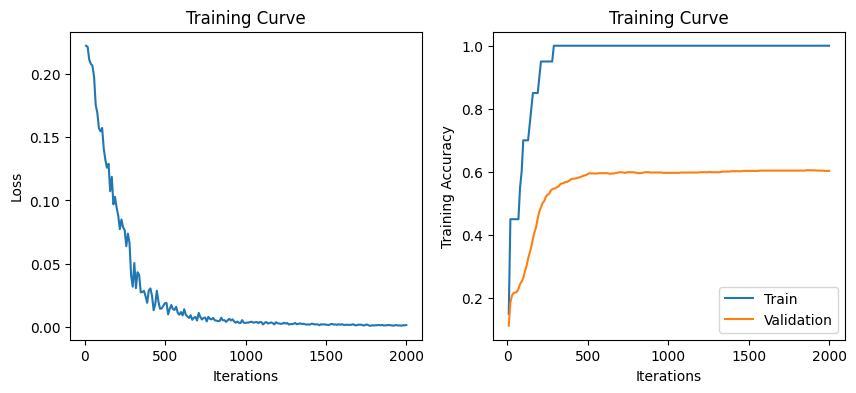

Final Training Accuracy: 1.0
Final Validation Accuracy: 0.6030612244897959


In [50]:
set_seed(42)
model = MNISTClassifier_parametrized(1000,100).to(device)
train(model, mnist_train, mnist_val, num_epochs=1000, with_plot=True)

Epoch 0, loss: 2.254729986190796
Epoch 100, loss: 1.4965845346450806
Epoch 200, loss: 1.1340450048446655
Epoch 300, loss: 0.8977095484733582
Epoch 400, loss: 0.6690517663955688
Epoch 500, loss: 0.4263395369052887
Epoch 600, loss: 0.3582145571708679
Epoch 700, loss: 0.24866536259651184
Epoch 800, loss: 0.3209816813468933
Epoch 900, loss: 0.15970122814178467


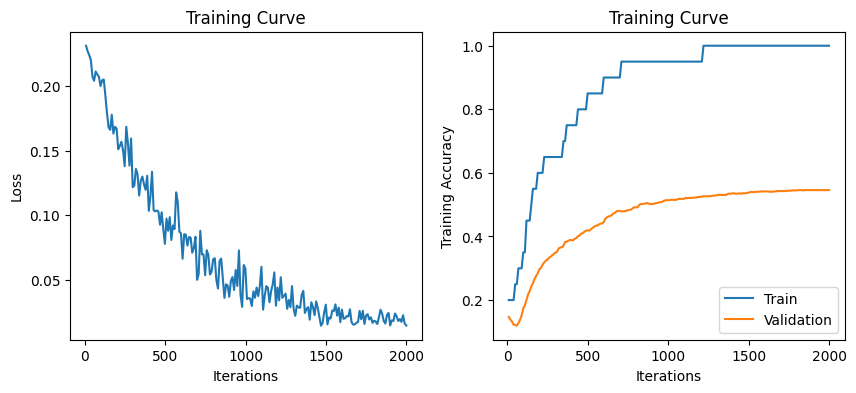

Final Training Accuracy: 1.0
Final Validation Accuracy: 0.5459183673469388


In [51]:
set_seed(42)
model = MNISTClassifier_parametrized(20,10).to(device)
train(model, mnist_train, mnist_val, num_epochs=1000, with_plot=True)

Epoch 0, loss: 2.254729986190796
Epoch 100, loss: 1.4965845346450806
Epoch 200, loss: 1.1340450048446655
Epoch 300, loss: 0.8977095484733582
Epoch 400, loss: 0.6690517663955688
Epoch 500, loss: 0.4263395369052887
Epoch 600, loss: 0.3582145571708679
Epoch 700, loss: 0.24866536259651184
Epoch 800, loss: 0.3209816813468933
Epoch 900, loss: 0.15970122814178467
Epoch 1000, loss: 0.20347347855567932
Epoch 1100, loss: 0.1338428109884262
Epoch 1200, loss: 0.1639551818370819
Epoch 1300, loss: 0.11704617738723755
Epoch 1400, loss: 0.05367622524499893
Epoch 1500, loss: 0.07571212202310562
Epoch 1600, loss: 0.09309002012014389
Epoch 1700, loss: 0.08849804848432541
Epoch 1800, loss: 0.04992974177002907
Epoch 1900, loss: 0.06278903782367706
Epoch 2000, loss: 0.0520642027258873
Epoch 2100, loss: 0.04334402456879616
Epoch 2200, loss: 0.041166506707668304
Epoch 2300, loss: 0.05300980806350708
Epoch 2400, loss: 0.04478836432099342
Epoch 2500, loss: 0.03580932691693306
Epoch 2600, loss: 0.038156885653734

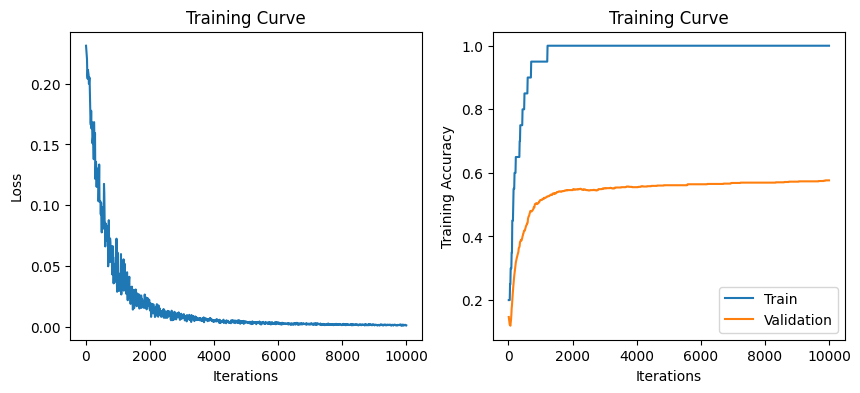

Final Training Accuracy: 1.0
Final Validation Accuracy: 0.576530612244898


In [52]:
set_seed(42)
model = MNISTClassifier_parametrized(20,10).to(device)
train(model, mnist_train, mnist_val, num_epochs=5000, with_plot=True)

## Architecture search

In [53]:
def fast_accuracy(model, data):
    with torch.no_grad():
        correct = 0
        total = 0
        model.eval()
        imgs, labels = data
        output = model(imgs.to(device))
        pred = output.max(1, keepdim=True)[1]
        correct += pred.eq(labels.view_as(pred).to(device)).sum().item()
        total += imgs.shape[0]
    return correct / total

def train_search(model, train, valid, batch_size=10, num_epochs=1, learn_rate=0.001, weight_decay=0):
    train_loader = torch.utils.data.DataLoader(train,
                                               batch_size=batch_size,
                                               shuffle=True) # shuffle after every epoch
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=learn_rate,momentum=0.9, weight_decay=weight_decay)

    iters, losses, train_acc, val_acc = [], [], [], []

    idx = 0
    for n in range(num_epochs):
        for imgs, labels in iter(train_loader):
            imgs, labels = imgs.to(device), labels.to(device)
            model.train()
            out = model(imgs)
            loss = criterion(out, labels)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

    return(fast_accuracy(model, valid))

In [54]:
mnist_val_preprocessed = torch.cat([batch[0] for batch in mnist_val]), torch.tensor([batch[1] for batch in mnist_val])

In [55]:
mnist_data = torchvision.datasets.MNIST('data', train=True, download=True, transform=transforms.ToTensor())
mnist_data = list(mnist_data)
mnist_train = mnist_data[:20]
mnist_val   = mnist_data[20:10000]

In [56]:
first_layer = [2000, 1000, 500, 100, 50, 10]
second_layer = [5000, 2000, 1000, 500, 100, 50, 10]

# # mniej parametrow
# first_layer = [50, 10]
# second_layer = [50, 10]

results = []
for i in range(len(first_layer)):
    for j in range(len(second_layer)):
        set_seed(42)
        model = MNISTClassifier_parametrized(first_layer[i],second_layer[j]).to(device)
        val_acc = train_search(model, mnist_train, mnist_val_preprocessed, num_epochs=1000)
        print(first_layer[i],second_layer[j],val_acc)
        results.append({"first": first_layer[i], "second": second_layer[j],"acc":val_acc})
results = pd.DataFrame(results)

2000 5000 0.6204081632653061
2000 2000 0.6112244897959184
2000 1000 0.6204081632653061
2000 500 0.6255102040816326
2000 100 0.6112244897959184
2000 50 0.5948979591836735
2000 10 0.5591836734693878
1000 5000 0.6122448979591837
1000 2000 0.6030612244897959
1000 1000 0.613265306122449
1000 500 0.6051020408163266
1000 100 0.6030612244897959
1000 50 0.6163265306122448
1000 10 0.5469387755102041
500 5000 0.6173469387755102
500 2000 0.6244897959183674
500 1000 0.6173469387755102
500 500 0.6153061224489796
500 100 0.6071428571428571
500 50 0.5836734693877551
500 10 0.560204081632653
100 5000 0.6091836734693877
100 2000 0.6061224489795919
100 1000 0.6051020408163266
100 500 0.6163265306122448
100 100 0.6010204081632653
100 50 0.5959183673469388
100 10 0.539795918367347
50 5000 0.6040816326530613
50 2000 0.5969387755102041
50 1000 0.5918367346938775
50 500 0.610204081632653
50 100 0.5969387755102041
50 50 0.5785714285714286
50 10 0.4969387755102041
10 5000 0.5959183673469388
10 2000 0.6061224489

In [57]:
results.to_csv("params_search.csv",index=False)
results = pd.read_csv("params_search.csv")

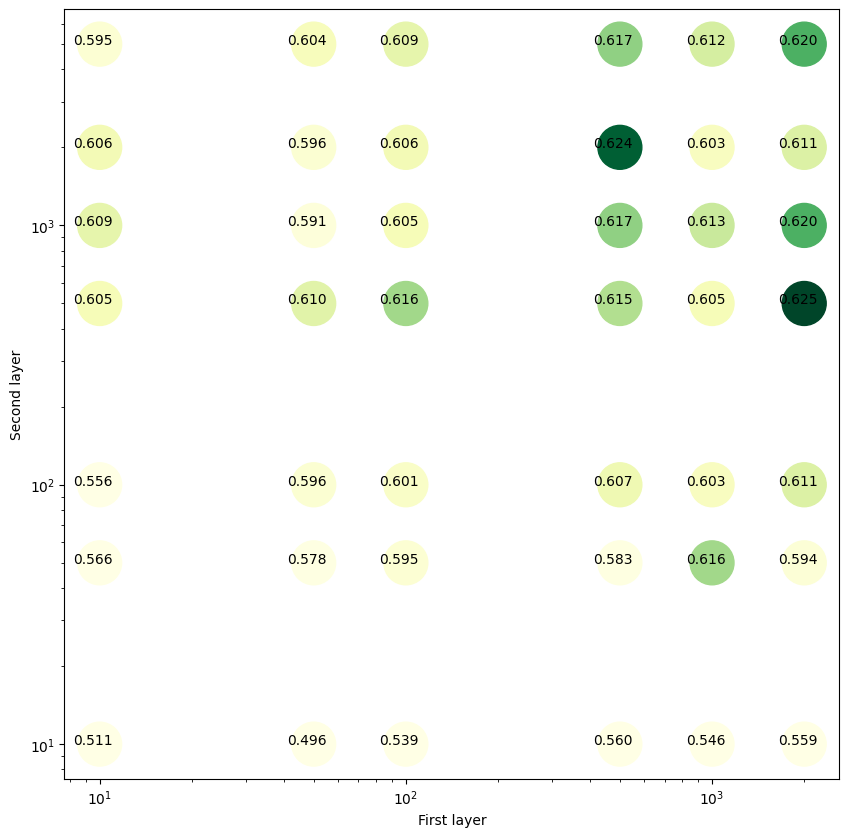

In [58]:
fig, ax = plt.subplots(figsize=(10,10))
ax.scatter(results["first"], results["second"], c=np.exp(results.acc*100), cmap="YlGn", s=1000)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("First layer")
plt.ylabel("Second layer")
for idx, row in results.iterrows():
    ax.annotate(str(row.acc)[:5], (row["first"]*0.82, row["second"]))
plt.show()

### Sieć o większej liczbie warstw wymaga dłuższego treningu

In [59]:
class MNISTClassifier_parametrized_3(nn.Module):
    def __init__(self,sizes):
        super(MNISTClassifier_parametrized_3, self).__init__()
        size_in = 28 * 28

        layers = []
        for size in sizes:
            layers.append(nn.Linear(size_in, size))
            layers.append(nn.Tanh())
            size_in = size
        layers.append(nn.Linear(size_in, 10))
        self.layers = nn.Sequential(*layers)

    def forward(self, img):
        flattened = img.view(-1, 28 * 28)
        
        output = self.layers(flattened)
        return output

Epoch 0, loss: 2.295598268508911


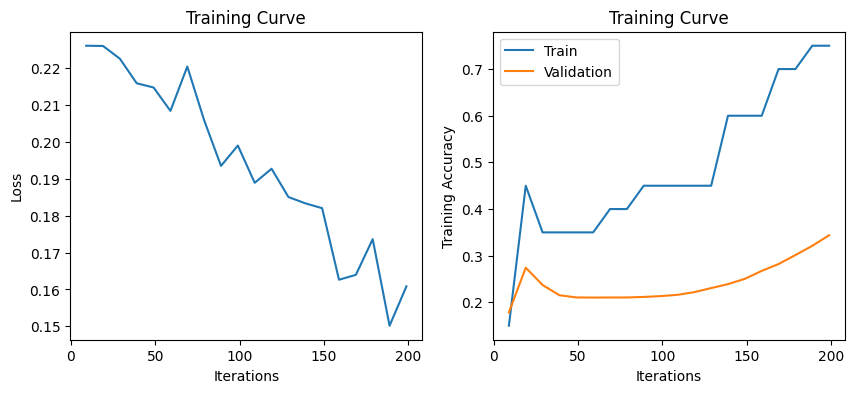

Final Training Accuracy: 0.75
Final Validation Accuracy: 0.3438877755511022


In [60]:
set_seed(42)
model = MNISTClassifier_parametrized_3([1000,500,100]).to(device)
train(model, mnist_train, mnist_val, num_epochs=100, with_plot=True)

Epoch 0, loss: 2.2922756671905518


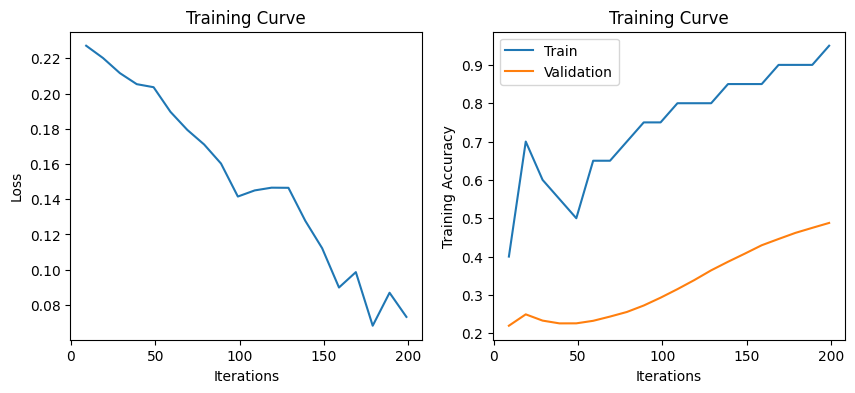

Final Training Accuracy: 0.95
Final Validation Accuracy: 0.4877755511022044


In [61]:
set_seed(42)
model = MNISTClassifier_parametrized_3([1000, 500]).to(device)
train(model, mnist_train, mnist_val, num_epochs=100, with_plot=True)

### Większa liczba warstw może prowadzić do przeuczania

Epoch 0, loss: 2.295598268508911
Epoch 100, loss: 1.4384117126464844
Epoch 200, loss: 0.45347538590431213
Epoch 300, loss: 0.15286779403686523
Epoch 400, loss: 0.08510484546422958
Epoch 500, loss: 0.04410169646143913
Epoch 600, loss: 0.02144094742834568
Epoch 700, loss: 0.020208504050970078
Epoch 800, loss: 0.014600086025893688
Epoch 900, loss: 0.014825509861111641
Epoch 1000, loss: 0.01273045502603054
Epoch 1100, loss: 0.013835340738296509
Epoch 1200, loss: 0.009723198600113392
Epoch 1300, loss: 0.006551964674144983
Epoch 1400, loss: 0.00740199675783515
Epoch 1500, loss: 0.004688636865466833
Epoch 1600, loss: 0.007544979453086853
Epoch 1700, loss: 0.005247766617685556
Epoch 1800, loss: 0.005166665650904179
Epoch 1900, loss: 0.00382457603700459


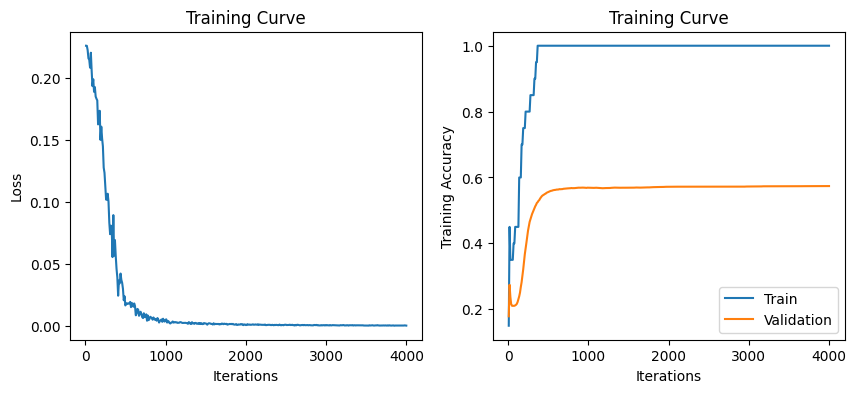

Final Training Accuracy: 1.0
Final Validation Accuracy: 0.5739478957915831


In [62]:
set_seed(42)
model = MNISTClassifier_parametrized_3([1000,500,100]).to(device)
train(model, mnist_train, mnist_val, num_epochs=2000, with_plot=True)

Epoch 0, loss: 2.2922756671905518
Epoch 100, loss: 0.9161934852600098
Epoch 200, loss: 0.07864376157522202
Epoch 300, loss: 0.06523127108812332
Epoch 400, loss: 0.032900501042604446
Epoch 500, loss: 0.021633289754390717
Epoch 600, loss: 0.01790931448340416
Epoch 700, loss: 0.012422947213053703
Epoch 800, loss: 0.008892877027392387
Epoch 900, loss: 0.010522556491196156
Epoch 1000, loss: 0.009742371737957
Epoch 1100, loss: 0.0074663832783699036
Epoch 1200, loss: 0.008362701162695885
Epoch 1300, loss: 0.006890275981277227
Epoch 1400, loss: 0.0037968135438859463
Epoch 1500, loss: 0.005193951074033976
Epoch 1600, loss: 0.004988308064639568
Epoch 1700, loss: 0.0029186431784182787
Epoch 1800, loss: 0.003945386502891779
Epoch 1900, loss: 0.0035423790104687214


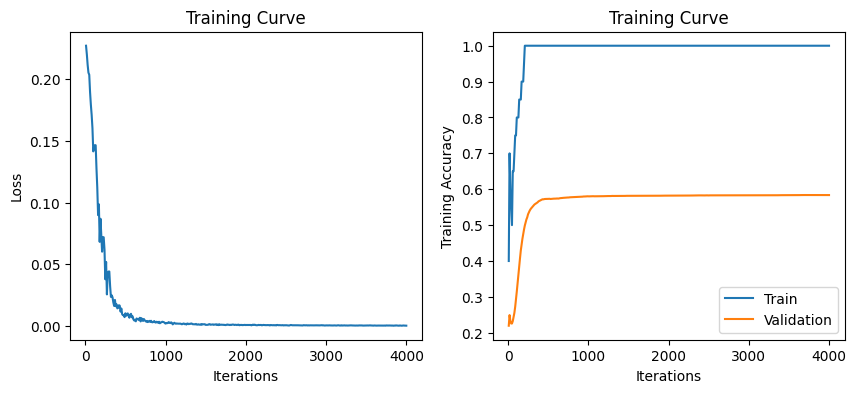

Final Training Accuracy: 1.0
Final Validation Accuracy: 0.5837675350701402


In [63]:
set_seed(42)
model = MNISTClassifier_parametrized_3([1000,500]).to(device)
train(model, mnist_train, mnist_val, num_epochs=2000, with_plot=True)

## Reprezentacje danych

In [65]:
adults_data_orig = pd.read_csv("https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data",header=None)

In [66]:
adults_data = adults_data_orig.copy()

In [67]:
adults_data.columns = ["age", "workclass", "fnlwgt", "education", "education-num", "marital-status", "occupation", "relationship", "race", "sex", "capital-gain", "capital-loss", "hours-per-week", "native-country", "label"]

In [68]:
adults_data.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,label
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [69]:
adults_data['native-country'].value_counts()

native-country
United-States                 29170
Mexico                          643
?                               583
Philippines                     198
Germany                         137
Canada                          121
Puerto-Rico                     114
El-Salvador                     106
India                           100
Cuba                             95
England                          90
Jamaica                          81
South                            80
China                            75
Italy                            73
Dominican-Republic               70
Vietnam                          67
Guatemala                        64
Japan                            62
Poland                           60
Columbia                         59
Taiwan                           51
Haiti                            44
Iran                             43
Portugal                         37
Nicaragua                        34
Peru                             31
France       

In [70]:
adults_data.drop(columns=["native-country","education","workclass","relationship", "marital-status","race"],inplace=True)

In [71]:
adults_data.head()

,age,fnlwgt,education-num,occupation,sex,capital-gain,capital-loss,hours-per-week,label
0,39,77516,13,Adm-clerical,Male,2174,0,40,<=50K
1,50,83311,13,Exec-managerial,Male,0,0,13,<=50K
2,38,215646,9,Handlers-cleaners,Male,0,0,40,<=50K
3,53,234721,7,Handlers-cleaners,Male,0,0,40,<=50K
4,28,338409,13,Prof-specialty,Female,0,0,40,<=50K


In [72]:
adults_data.sex = (adults_data.sex==' Male').astype(int)
adults_data.label = (adults_data.label==' >50K').astype(int)

In [73]:
adults_data.head()

,age,fnlwgt,education-num,occupation,sex,capital-gain,capital-loss,hours-per-week,label
0,39,77516,13,Adm-clerical,1,2174,0,40,0
1,50,83311,13,Exec-managerial,1,0,0,13,0
2,38,215646,9,Handlers-cleaners,1,0,0,40,0
3,53,234721,7,Handlers-cleaners,1,0,0,40,0
4,28,338409,13,Prof-specialty,0,0,0,40,0


### Get dummies

Dane kategoryczne -> one-hot encoding

In [74]:
adults_data['occupation'].value_counts()

occupation
Prof-specialty       4140
Craft-repair         4099
Exec-managerial      4066
Adm-clerical         3770
Sales                3650
Other-service        3295
Machine-op-inspct    2002
?                    1843
Transport-moving     1597
Handlers-cleaners    1370
Farming-fishing       994
Tech-support          928
Protective-serv       649
Priv-house-serv       149
Armed-Forces            9
Name: count, dtype: int64

In [75]:
categorical_columns = ["occupation"]
categorical_values = pd.get_dummies(adults_data[categorical_columns]).astype(int)

categorical_values.head()

,occupation_ ?,occupation_ Adm-clerical,occupation_ Armed-Forces,occupation_ Craft-repair,occupation_ Exec-managerial,occupation_ Farming-fishing,occupation_ Handlers-cleaners,occupation_ Machine-op-inspct,occupation_ Other-service,occupation_ Priv-house-serv,occupation_ Prof-specialty,occupation_ Protective-serv,occupation_ Sales,occupation_ Tech-support,occupation_ Transport-moving
0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0


In [76]:
adults_data.drop(columns=categorical_columns,inplace=True)

In [77]:
adults_data.head()

,age,fnlwgt,education-num,sex,capital-gain,capital-loss,hours-per-week,label
0,39,77516,13,1,2174,0,40,0
1,50,83311,13,1,0,0,13,0
2,38,215646,9,1,0,0,40,0
3,53,234721,7,1,0,0,40,0
4,28,338409,13,0,0,0,40,0


In [78]:
train_indices = np.random.rand(len(adults_data))>0.3

In [79]:
numerical_data = torch.from_numpy(adults_data.values[train_indices,:-1]).float()
categorical_data = torch.from_numpy(categorical_values.values[train_indices]).float()
targets = torch.from_numpy(adults_data.values[train_indices,-1]).float()

test_numerical_data = torch.from_numpy(adults_data.values[~train_indices,:-1]).float()
test_categorical_data = torch.from_numpy(categorical_values.values[~train_indices]).float()
test_targets = torch.from_numpy(adults_data.values[~train_indices,-1]).float()

In [80]:
train_dataset = data.TensorDataset(numerical_data,categorical_data,targets)
test_dataset = data.TensorDataset(test_numerical_data,test_categorical_data,test_targets)

In [81]:
train_dataset[0]

(tensor([3.9000e+01, 7.7516e+04, 1.3000e+01, 1.0000e+00, 2.1740e+03, 0.0000e+00,
         4.0000e+01]),
 tensor([0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]),
 tensor(0.))

### Cat numerical and categorical data

In [82]:
class Adults_classifier(nn.Module):
    def __init__(self):
        super(Adults_classifier, self).__init__()
        self.layer1 = nn.Linear(adults_data.shape[1] + categorical_data.shape[1] -1, 40)
        self.act_1 = nn.LeakyReLU()
        self.d1 = nn.Dropout(0.4)
        self.layer2 = nn.Linear(40, 20)
        self.act_2 = nn.LeakyReLU()
        self.d2 = nn.Dropout(0.4)
        self.layer3 = nn.Linear(20, 1)
    def forward(self, x, cat_x):
        x = torch.cat([x,cat_x],dim=1)
        activation1 = self.act_1(self.layer1(x))
        activation1 = self.d1(activation1)
        activation2 = self.act_2(self.layer2(activation1))
        activation2 = self.d1(activation2)
        output = self.layer3(activation2)
        return output

In [83]:
def get_accuracy(model, data_loader):
    correct = 0
    total = 0
    model.eval() #*********#
    for x, cat_x, labels in data_loader:
        x, cat_x, labels = x.to(device), cat_x.to(device), labels.to(device)
        output = model(x, cat_x)
        pred = output>0
        correct += pred.eq(labels.view_as(pred)).sum().item()
        total += x.shape[0]
    return correct / total

In [84]:
set_seed(42)
model = Adults_classifier().to(device)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=128, shuffle=False)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=0.001)

iters = []
losses = []
train_acc = []
val_acc = []
for n in range(10):
    epoch_losses = []
    model.train()
    for x, cat_x, labels in iter(train_loader):
        optimizer.zero_grad()
        x, cat_x, labels = x.to(device), cat_x.to(device), labels.to(device)
        out = model(x, cat_x).squeeze()
        loss = criterion(out, labels)
        loss.backward()
        epoch_losses.append(loss.item())
        optimizer.step()

    loss_mean = np.array(epoch_losses).mean()
    iters.append(n)
    losses.append(loss_mean)
    test_acc = get_accuracy(model, test_loader)
    print(f"Epoch {n} loss {loss_mean:.3} test_acc: {test_acc:.3}")
    train_acc.append(get_accuracy(model, train_loader)) # compute training accuracy
    val_acc.append(test_acc)  # compute validation accuracy


print("Final Training Accuracy: {}".format(train_acc[-1]))
print("Final Validation Accuracy: {}".format(val_acc[-1]))

Epoch 0 loss 3.5e+02 test_acc: 0.762
Epoch 1 loss 28.0 test_acc: 0.762
Epoch 2 loss 18.8 test_acc: 0.764
Epoch 3 loss 11.5 test_acc: 0.765
Epoch 4 loss 7.8 test_acc: 0.765
Epoch 5 loss 5.11 test_acc: 0.766
Epoch 6 loss 3.24 test_acc: 0.767
Epoch 7 loss 2.26 test_acc: 0.767
Epoch 8 loss 1.34 test_acc: 0.768
Epoch 9 loss 0.865 test_acc: 0.768
Final Training Accuracy: 0.7662679111344814
Final Validation Accuracy: 0.7681724845995893


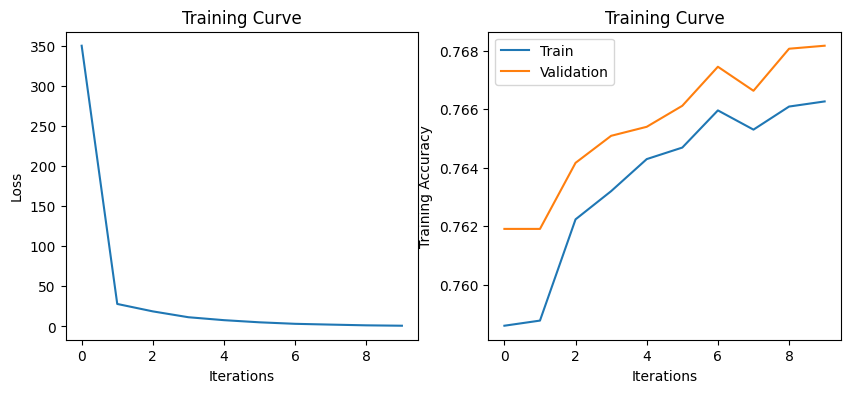

In [85]:
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.title("Training Curve")
plt.plot(iters, losses, label="Train")
plt.xlabel("Iterations")
plt.ylabel("Loss")

plt.subplot(1,2,2)
plt.title("Training Curve")
plt.plot(iters, train_acc, label="Train")
plt.plot(iters, val_acc, label="Validation")
plt.xlabel("Iterations")
plt.ylabel("Training Accuracy")
plt.legend(loc='best')
plt.show()

array([[<Axes: title={'center': 'gts'}>]], dtype=object)

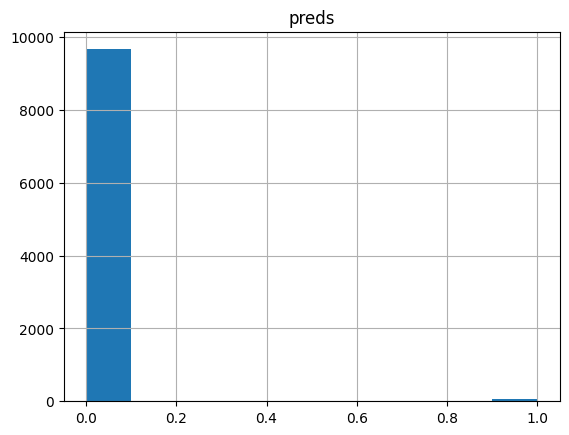

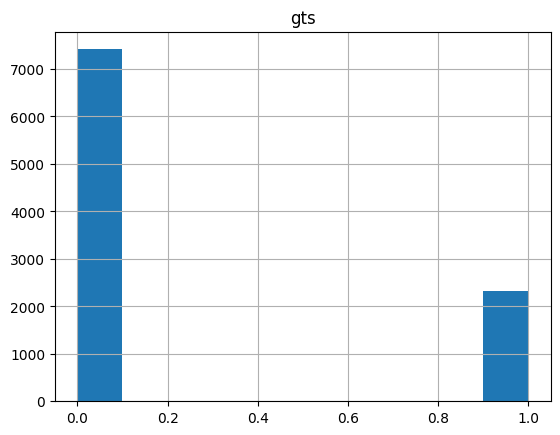

In [86]:
model.eval() #*********#
preds = []
gts = []
for x, cat_x, labels in test_loader:
    x, cat_x, labels = x.to(device), cat_x.to(device), labels.to(device)
    output = model(x, cat_x)
    pred = output>0
    preds.append(pred.cpu().detach().numpy())
    gts.append(labels.cpu().detach().numpy())
preds = np.concatenate(preds)
gts = np.concatenate(gts)

pd.DataFrame(preds.squeeze(), columns=["preds"]).astype(int).hist()
pd.DataFrame(gts.squeeze(), columns=["gts"]).astype(int).hist()

## Embeddings

In [87]:
class Adults_classifier_embeddings(nn.Module):
    def __init__(self):
        super(Adults_classifier_embeddings, self).__init__()
        self.emb_layer = nn.Linear(categorical_data.shape[1], categorical_data.shape[1])
        self.act_emb = nn.Tanh()
        self.layer1 = nn.Linear(adults_data.shape[1] -1 + categorical_data.shape[1], 40)
        self.act_1 =  nn.LeakyReLU()
        self.d1 = nn.Dropout(0.4)
        self.layer2 = nn.Linear(40, 20)
        self.act_2 =  nn.LeakyReLU()
        self.d2 = nn.Dropout(0.4)
        self.layer3 = nn.Linear(20, 1)
    def forward(self, x, cat_x):
        cat_x_embedded = self.emb_layer(cat_x)
        cat_x_embedded = self.act_emb(cat_x_embedded)
        x = torch.cat([x,cat_x_embedded],dim=1)
        activation1 = self.act_1(self.layer1(x))
        activation1 = self.d1(activation1)
        activation2 = self.act_2(self.layer2(activation1))
        activation2 = self.d2(activation2)
        output = self.layer3(activation2)
        return output

In [ ]:
set_seed(42)
model = Adults_classifier_embeddings().to(device)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=128, shuffle=False)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

iters = []
losses = []
train_acc = []
val_acc = []
for n in range(10):
    epoch_losses = []
    for x, cat_x, labels in iter(train_loader):
        x, cat_x, labels = x.to(device), cat_x.to(device), labels.to(device)
        model.train()
        out = model(x, cat_x).squeeze()

        loss = criterion(out, labels)
        loss.backward()
        epoch_losses.append(loss.item())
        optimizer.step()
        optimizer.zero_grad()

    loss_mean = np.array(epoch_losses).mean()
    iters.append(n)
    losses.append(loss_mean)
    test_acc = get_accuracy(model, test_loader)
    print(f"Epoch {n} loss {loss_mean:.3} test_acc: {test_acc:.3}")
    train_acc.append(get_accuracy(model, train_loader)) # compute training accuracy
    val_acc.append(test_acc)  # compute validation accuracy


print("Final Training Accuracy: {}".format(train_acc[-1]))
print("Final Validation Accuracy: {}".format(val_acc[-1]))

Epoch 0 loss 1.59e+02 test_acc: 0.765
Epoch 1 loss 8.24 test_acc: 0.765
Epoch 2 loss 5.12 test_acc: 0.767
Epoch 3 loss 3.11 test_acc: 0.765
Epoch 4 loss 1.89 test_acc: 0.766
Epoch 5 loss 1.17 test_acc: 0.767
Epoch 6 loss 0.833 test_acc: 0.768
Epoch 7 loss 0.673 test_acc: 0.768
Epoch 8 loss 0.608 test_acc: 0.768
Epoch 9 loss 0.586 test_acc: 0.769
Final Training Accuracy: 0.7668375618947461
Final Validation Accuracy: 0.7685831622176591


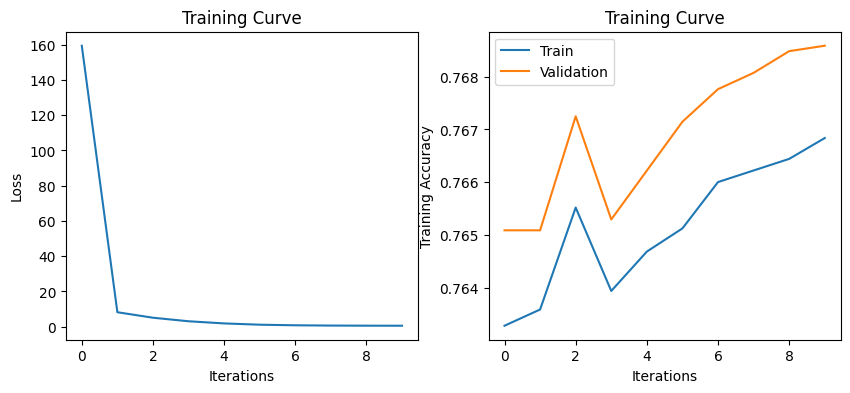

In [89]:
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.title("Training Curve")
plt.plot(iters, losses, label="Train")
plt.xlabel("Iterations")
plt.ylabel("Loss")

plt.subplot(1,2,2)
plt.title("Training Curve")
plt.plot(iters, train_acc, label="Train")
plt.plot(iters, val_acc, label="Validation")
plt.xlabel("Iterations")
plt.ylabel("Training Accuracy")
plt.legend(loc='best')
plt.show()

In [90]:
(preds<=0).sum(), (preds>0).sum()

(np.int64(9670), np.int64(70))

## Ważenie przykładów

- mówimy modelowi ze dla przykładów trudnych loss ma byc skalowany do duzo wyzszej wartosci niz dla przykladow prostszych (prostych = nieproporcjonalnie częściej występujących)

In [91]:
(len(targets)-sum(targets))/sum(targets)

tensor(3.1365)

In [92]:
model = Adults_classifier_embeddings().to(device)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=128, shuffle=False)
criterion = nn.BCEWithLogitsLoss(pos_weight=(len(targets)-sum(targets))/sum(targets))
optimizer = optim.Adam(model.parameters(), lr=1e-3)

iters = []
losses = []
train_acc = []
val_acc = []
for n in range(30):
    epoch_losses = []
    for x, cat_x, labels in iter(train_loader):
        x, cat_x, labels = x.to(device), cat_x.to(device), labels.to(device)
        model.train()
        out = model(x, cat_x).squeeze()

        loss = criterion(out, labels)
        loss.backward()
        epoch_losses.append(loss.item())
        optimizer.step()
        optimizer.zero_grad()

    loss_mean = np.array(epoch_losses).mean()
    iters.append(n)
    losses.append(loss_mean)
    test_acc = get_accuracy(model, test_loader)
    print(f"Epoch {n} loss {loss_mean:.3} test_acc: {test_acc:.3}")
    train_acc.append(get_accuracy(model, train_loader)) # compute training accuracy
    val_acc.append(test_acc)  # compute validation accuracy


print("Final Training Accuracy: {}".format(train_acc[-1]))
print("Final Validation Accuracy: {}".format(val_acc[-1]))

Epoch 0 loss 5.69e+02 test_acc: 0.239
Epoch 1 loss 50.1 test_acc: 0.239
Epoch 2 loss 33.0 test_acc: 0.778
Epoch 3 loss 21.9 test_acc: 0.787
Epoch 4 loss 12.9 test_acc: 0.783
Epoch 5 loss 7.48 test_acc: 0.786
Epoch 6 loss 4.36 test_acc: 0.239
Epoch 7 loss 2.49 test_acc: 0.263
Epoch 8 loss 1.73 test_acc: 0.278
Epoch 9 loss 1.41 test_acc: 0.375
Epoch 10 loss 1.23 test_acc: 0.311
Epoch 11 loss 1.14 test_acc: 0.766
Epoch 12 loss 1.13 test_acc: 0.311
Epoch 13 loss 1.13 test_acc: 0.401
Epoch 14 loss 1.11 test_acc: 0.238
Epoch 15 loss 1.14 test_acc: 0.237
Epoch 16 loss 1.16 test_acc: 0.765
Epoch 17 loss 1.11 test_acc: 0.765
Epoch 18 loss 1.12 test_acc: 0.239
Epoch 19 loss 1.1 test_acc: 0.239
Epoch 20 loss 1.14 test_acc: 0.239
Epoch 21 loss 1.1 test_acc: 0.758
Epoch 22 loss 1.1 test_acc: 0.239
Epoch 23 loss 1.13 test_acc: 0.742
Epoch 24 loss 1.09 test_acc: 0.51
Epoch 25 loss 1.06 test_acc: 0.239
Epoch 26 loss 1.05 test_acc: 0.792
Epoch 27 loss 1.01 test_acc: 0.792
Epoch 28 loss 1.03 test_acc: 0

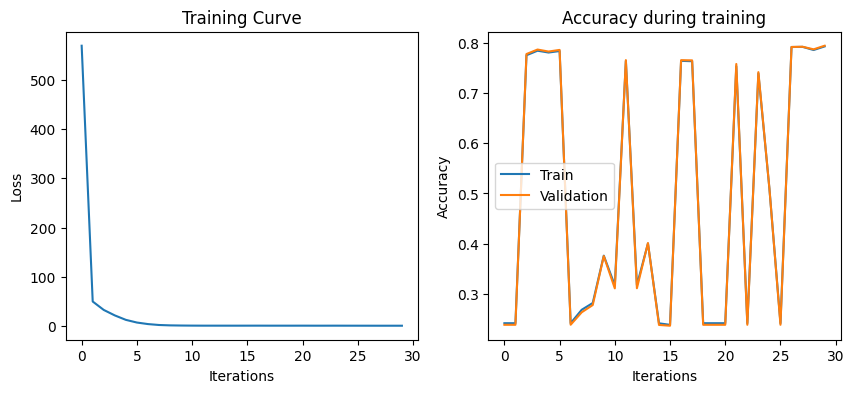

In [93]:
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.title("Training Curve")
plt.plot(iters, losses, label="Train")
plt.xlabel("Iterations")
plt.ylabel("Loss")

plt.subplot(1,2,2)
plt.title("Accuracy during training")
plt.plot(iters, train_acc, label="Train")
plt.plot(iters, val_acc, label="Validation")
plt.xlabel("Iterations")
plt.ylabel("Accuracy")
plt.legend(loc='best')
plt.show()

array([[<Axes: title={'center': 'gts'}>]], dtype=object)

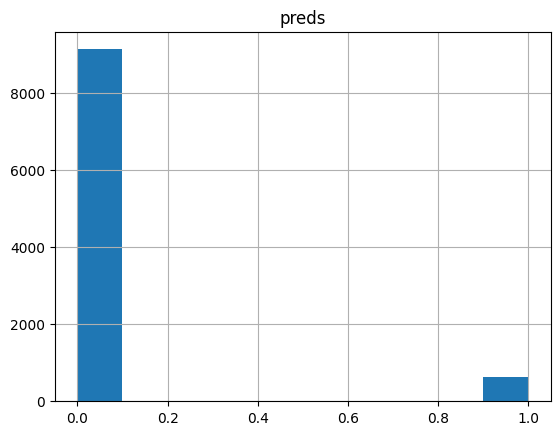

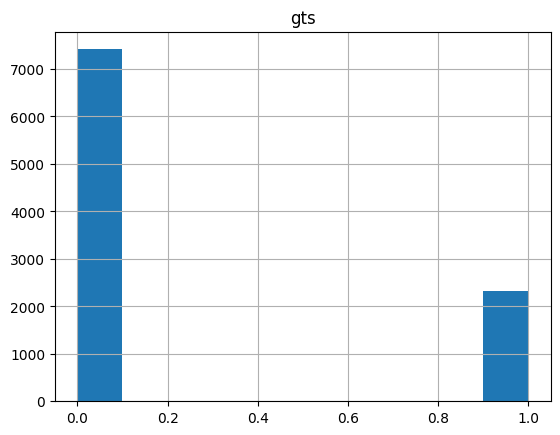

In [94]:
model.eval() #*********#
preds = []
gts = []
for x, cat_x, labels in test_loader:
    x, cat_x, labels = x.to(device), cat_x.to(device), labels.to(device)
    output = model(x, cat_x)
    pred = output>0
    preds.append(pred.cpu().detach().numpy())
    gts.append(labels.cpu().detach().numpy())
preds = np.concatenate(preds)
gts = np.concatenate(gts)

pd.DataFrame(preds.squeeze(), columns=["preds"]).astype(int).hist()
pd.DataFrame(gts.squeeze(), columns=["gts"]).astype(int).hist()

Bonus: https://imbalanced-learn.org/stable/index.html

![](https://www.researchgate.net/profile/Vinod-Kumar-159/publication/361949774/figure/fig2/AS:1177230768119815@1657685095263/Oversampling-and-undersampling-process.png)